In [17]:
import numpy as np
import random
from scipy.linalg import expm as exp
from scipy.linalg import qr, svd
from tqdm import tqdm
import scipy
import math
import matplotlib.pyplot as plt

In [18]:
def H(num):
    H = np.diag(np.ones(num-1),-1)+np.diag(np.ones(num-1),1)
    H[num-1,0]=H[0,num-1]=1

    return H

In [19]:
def initial(num):
    U = np.zeros((num,num//2),dtype=np.complex_)
    for i in range(num//2):
        U[2*i,i]=1+0*1j
    return U, qr(U,mode='economic')[0]

def normalize(U):
    L, N = U.shape
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 

In [20]:

def generate_gaussian_noise(num_points, num_channels, gamma, dt):
    std_dev = np.sqrt(gamma * dt)
    noise = np.random.normal(loc=0.0, scale=std_dev, size=(num_channels, num_points))
    return noise


In [480]:
num_points = 100000  # Number of time points
num_channels = 1  # Number of spatial indices
gamma = 1.0        # Variance scaling
dt = 0.01          # Time step size

np.std(generate_gaussian_noise(100000, 1, gamma, dt)[:1,:10][0])**2

0.00900022379046975

In [21]:

def evolution(U_i,H,gamma,dt):
    D = np.dot(U_i,U_i.conjugate().T)
    nj= np.diag(D).real
    
    M=np.zeros((U_i.shape[0],U_i.shape[0]),dtype=np.complex_)
    for i in range(U_i.shape[0]):
        M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma*dt))/dt+gamma*(2*nj[i]-1)/2

    h = H+1j*M
    U = np.dot(scipy.linalg.expm(-1j*h*dt),U_i)
    
    return U,normalize(U),nj[0],nj[1] #qr_householder(U)[0],


    


In [23]:
def evolution(U_i,H,gamma,dt):
    N = U_i@U_i.conj().T
    nj= np.diag(N).real
    M = np.zeros((U_i.shape[0],U_i.shape[0]), dtype=np.complex_)
    for i in range(U_i.shape[0]):
        M[i,i] = random.gauss(mu =0, sigma= np.sqrt(gamma*dt))+ gamma*(2*nj[i]-1)*dt

    U_tdt =  exp(M)@exp(-1j*H*dt)@U_i
    U_tnorm = normalize(U_tdt)
    
    return qr(U_tdt,mode= 'economic')[0],U_tdt, U_tnorm,nj[0],nj[1]

In [24]:
def evolutionx(U_i,H,gamma,dt):
    N = U_i@U_i.conj().T
    nj= np.diag(N).real
    Noise = np.diag(generate_gaussian_noise(U_i.shape[0], 1, gamma, dt)[0])
    M = np.zeros((U_i.shape[0],U_i.shape[0]), dtype=np.complex_)
    
    for i in range(U_i.shape[0]):
        M[i,i] =  Noise[i,i]+ gamma*(2*nj[i]-1)*dt

    U_tdt =  exp(M)@exp(-1j*H*dt)@U_i
    U_tnorm = normalize(U_tdt)
    
    return qr(U_tdt,mode= 'economic')[0], U_tnorm,nj[0],nj[1]

In [345]:
def evolutionx(U_i,H,gamma,dt):
    N = U_i@U_i.conj().T
    nj= np.diag(N).real
    M = np.zeros((U_i.shape[0],U_i.shape[0]), dtype=np.complex_)


    for i in range(U_i.shape[0]):
        if nj[i] !=0: M[i,i] = random.gauss(mu =0, sigma= np.sqrt(gamma*dt))+ gamma*(2*nj[i]-1)*dt

    U_tdt =  exp(M)@exp(-1j*H*dt)@U_i
    U_tnorm = normalize(U_tdt)
    
    return qr(U_tdt,mode= 'economic')[0], U_tnorm,nj[0],nj[1]

In [343]:
U_i,_ = initial(6)
N = U_i@U_i.conj().T
nj= np.diag(N).real
gamma = 0.02
dt =0.05


M = np.zeros((U_i.shape[0],U_i.shape[0],), dtype=np.complex_)
for i in range(U_i.shape[0]):
    if nj[i] !=0: M[i,i] = np.round(random.gauss(mu =0, sigma= np.sqrt(gamma*dt))+ gamma*(2*nj[i]-1)*dt/2,3)

In [25]:
def entropy(x):
    x= x.real
    eps = 1e-10  # Small value to prevent log2(0)
    
    # Clamp x within [eps, 1 - eps] to avoid log2(0) errors
    if x <= eps or x >= 1 - eps:
        return 0
    
    return -(x*math.log2(x)+ (1-x)*math.log2(1-x))

In [26]:
def sin(x,L):
    return math.sin(math.pi*x/L)

In [221]:
N=150
dt = 0.05
time = np.arange(0,N+dt,dt)
Dm = []
Dm2= []
Ham =H(100)
U_init, _ = initial(100)
for t in tqdm(range(len(time))):
    if t==0: Dm2.append(U_init)
    
    Dm.append(U_init)
    
    U_initx,U_init,_,_ = evolutionx(U_init,Ham,0,dt)
    Dm2.append(U_initx)




100%|██████████| 3001/3001 [01:11<00:00, 42.04it/s]


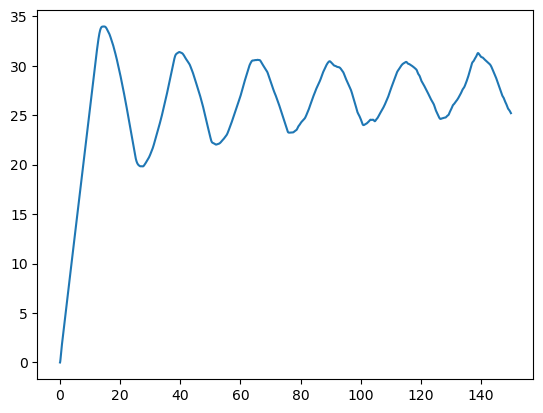

In [222]:
Matrix = [(x@x.conj().T).T for x in Dm]
Mat2 = [Matrix[i][:50,:50] for i in range(len(Matrix))]
alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]



S = []
for i in range(len(alleigval)):
    S.append(np.sum([entropy(x) for x in alleigval[i]]))
plt.plot(time,S)

In [7]:
# For the measurement case we need to to trajectory averages for the same

N=150
dt = 0.5
time = np.arange(0,N+dt,dt)
traj = 10


traj_entropies = []


for traj in tqdm(range(traj)):
    Dm = []

    Ham =H(100)
    _,U_init = initial(100)
    for t in range(len(time)):    
        Dm.append(U_init)    
        U_init,_,_,_ = evolution(U_init,Ham,0.1,dt)


    Matrix = [(x@x.conj().T).T for x in Dm]
    Mat2 = [Matrix[i][:25,:25] for i in range(len(Matrix))]
    alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]



    S = []
    for i in range(len(alleigval)):
        S.append(np.sum([entropy(x) for x in alleigval[i]]))
    
    traj_entropies.append(S)


average_entropy = np.mean(traj_entropies, axis=0)
plt.plot(time,average_entropy)

  0%|          | 0/10 [00:00<?, ?it/s]


NameError: name 'evolutionx' is not defined

In [204]:
# For the measurement case we need to to trajectory averages for the same

N=150
dt = 0.01
time = np.arange(0,N+dt,dt)
traj = 10

gamma_values = [0.05,0.1,0.2,0.3,0.4,0.6,0.8,1.0,2.0,4.0,6.0]
gamma_entropies = {}

for gamma in tqdm(gamma_values):
    traj_entropies = []
    
    for t in range(traj):
        
        Dm = []

        Ham =H(50)
        U_init, _ = initial(50)
        for t in range(len(time)):    
            Dm.append(U_init)    
            U_initx,U_init,_,_ = evolution(U_init,Ham,gamma,dt)


        Matrix = [(x@x.conj().T).T for x in Dm]
        Mat2 = [Matrix[i][:25,:25] for i in range(len(Matrix))]
        alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]
        S = []
        for i in range(len(alleigval)):
            S.append(np.sum([entropy(x) for x in alleigval[i]]))        
        traj_entropies.append(S)


    average_entropy = np.mean(traj_entropies, axis=0)


    gamma_entropies[gamma] = average_entropy



100%|██████████| 11/11 [2:13:19<00:00, 727.19s/it] 


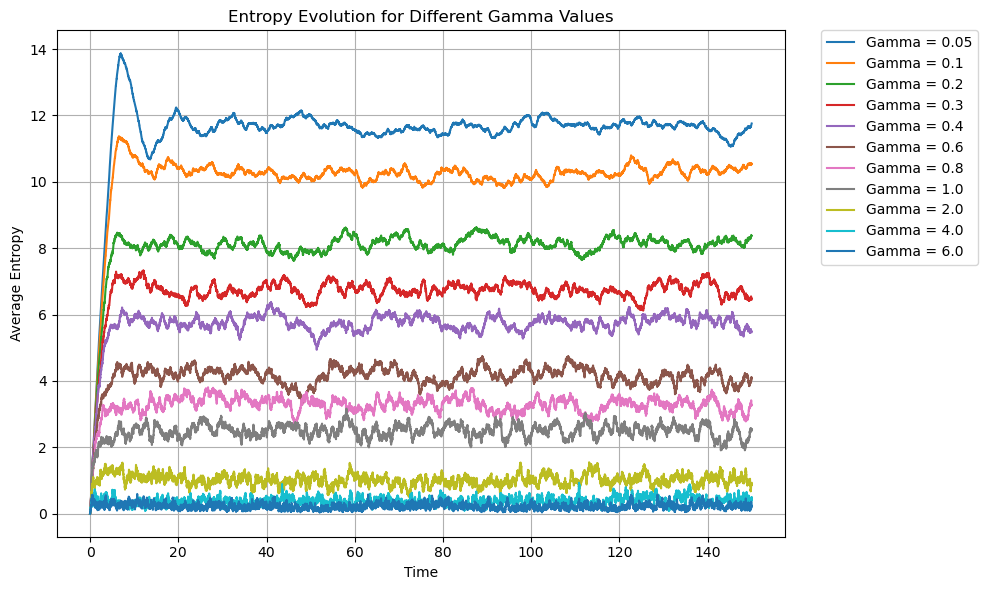

In [206]:
plt.figure(figsize=(10, 6))
for gamma, avg_entropy in gamma_entropies.items():
    plt.plot(time, avg_entropy, label=f"Gamma = {gamma}")

plt.xlabel("Time")
plt.ylabel("Average Entropy")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0)  # Move the legend outside
plt.title("Entropy Evolution for Different Gamma Values")
plt.grid()
plt.tight_layout()  # Adjust the layout to avoid clipping
plt.show()

In [ ]:
l= [2,8,14,20,28,38,44,52,62,72,80,82,84,86,88,90,92,93,94,95,96,97,98,100]



f_val= [ sin(i,200) for i in l]


# we have gamma_sentropiesx for dt = 0.5 and t = 10 L = 50

N=100
dt = 0.05
time = np.arange(0,N+dt,dt)
traj = 1
Ham =H(200)

gamma_values = [ 0.02, 0.05, 0.075,0.1,0.2, 0.5]
g_val2 = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 2.0]
gamma_entropi = {}
gamma_entropiesx = {}

for g in tqdm(gamma_values):
    traj_entropies = []

    for t in tqdm(range(traj)):
        

        
        U_init, _ = initial(200)

        for t in range(len(time)):       
            U_initx,U_init,_,_ = evolutionx(U_init,Ham,g,dt)



        Matrix = (U_init@U_init.conj().T).T
        Mat2 = [Matrix[:x,:x] for x in l]
        alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]



        S = []
        for i in range(len(alleigval)):
            S.append(np.sum([entropy(x) for x in alleigval[i]]))

        traj_entropies.append(S)

    gamma_entropi[g]=np.mean(traj_entropies,axis=0)

 


In [74]:
l= [2,8,14,20,28,38,44,52,62,72,80,82,84,86,88,90,92,93,94,95,96,97,98,100]



f_val= [ sin(i,200) for i in l]


# we have gamma_sentropiesx for dt = 0.5 and t = 10 L = 50

N=100
dt = 0.05
time = np.arange(0,N+dt,dt)
traj = 50
Ham =H(200)

gamma_values = [ 0.02, 0.05, 0.075,0.1,0.2, 0.5]
g_val2 = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 2.0]
gamma_entropies = {}
gamma_entropiesx = {}

for g in tqdm(gamma_values):
    traj_entropies = []

    for t in tqdm(range(traj)):
        

        
        U_init, _ = initial(200)

        for t in range(len(time)):       
            U_initx,U_init,_,_ = evolutionx(U_init,Ham,g,dt)



        Matrix = (U_init@U_init.conj().T).T
        Mat2 = [Matrix[:x,:x] for x in l]
        alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]



        S = []
        for i in range(len(alleigval)):
            S.append(np.sum([entropy(x) for x in alleigval[i]]))

        traj_entropies.append(S)

    gamma_entropies[g]=np.mean(traj_entropies,axis=0)

 


100%|██████████| 6/6 [1:11:07<00:00, 711.30s/it]


In [296]:
gamma_sentropies

{6.0: array([0.12178863, 0.15077773, 0.14365369, 0.06839334, 0.29542666,
        0.18281943, 0.2049999 , 0.20292365, 0.06915665, 0.17555545,
        0.21172148, 0.09877807, 0.10540872, 0.12924259, 0.06784785,
        0.10097022, 0.17143662, 0.0740585 , 0.09468899, 0.09070649,
        0.21064044, 0.1423852 , 0.1309074 , 0.11323682, 0.07003118])}

In [292]:
A= np.array([[1,2],[2,3],[4,5]])
print( np.mean(A, axis=0) )
print( np.mean(A, axis=1) )

[2.33333333 3.33333333]
[1.5 2.5 4.5]


In [34]:
l= np.arange(2,402,2)
f_val= [ sin(i,200) for i in l]


N=100
dt = 0.5
time = np.arange(0,N+dt,dt)
traj = 1

gamma_values = 0
gamma_sentropies = {}



traj_entropies = []




Ham =H(800)
U_init,_ = initial(800)
for t in tqdm(range(len(time))):       
    _,U_init,_,_ = evolutionx(U_init,Ham,0,dt)



Matrix = (U_init@U_init.conj().T).T
Mat2 = [Matrix[:x,:x] for x in l]
alleigval = [np.linalg.eig(Mat2[i])[0].real for i in range(len(Mat2))]



S = []
for i in tqdm(range(len(alleigval))):
    S.append(np.round(np.sum([entropy(x) for x in alleigval[i]]),3))

traj_entropies.append(S)



S



100%|██████████| 200/200 [00:00<00:00, 5333.31it/s]


[1.998,
 3.991,
 5.979,
 7.963,
 9.943,
 11.917,
 13.887,
 15.851,
 17.811,
 19.765,
 21.714,
 23.658,
 25.596,
 27.527,
 29.453,
 31.372,
 33.284,
 35.19,
 37.088,
 38.979,
 40.863,
 42.74,
 44.61,
 46.472,
 48.327,
 50.175,
 52.016,
 53.85,
 55.678,
 57.498,
 59.312,
 61.118,
 62.918,
 64.712,
 66.498,
 68.279,
 70.052,
 71.819,
 73.579,
 75.333,
 77.079,
 78.819,
 80.553,
 82.28,
 84.001,
 85.715,
 87.422,
 89.122,
 90.816,
 92.503,
 94.184,
 95.858,
 97.526,
 99.186,
 100.84,
 102.488,
 104.129,
 105.763,
 107.39,
 109.011,
 110.625,
 112.232,
 113.833,
 115.427,
 117.014,
 118.594,
 120.168,
 121.735,
 123.295,
 124.848,
 126.395,
 127.935,
 129.467,
 130.993,
 132.512,
 134.025,
 135.53,
 137.028,
 138.52,
 140.005,
 141.483,
 142.953,
 144.417,
 145.874,
 147.324,
 148.766,
 150.202,
 151.631,
 153.052,
 154.467,
 155.875,
 157.275,
 158.668,
 160.054,
 161.433,
 162.804,
 164.169,
 165.526,
 166.875,
 168.218,
 169.553,
 170.881,
 172.201,
 173.515,
 174.82,
 176.118,
 177.409,

(0.0, 40.0)

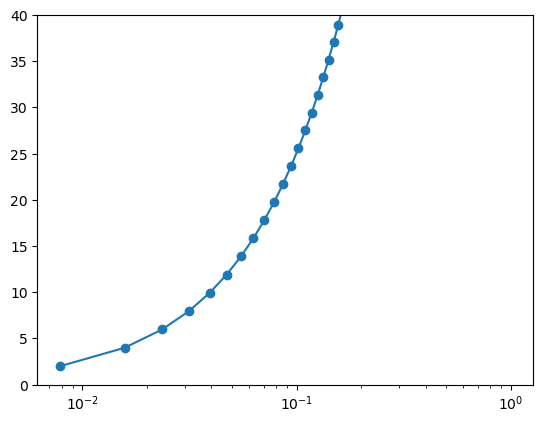

In [35]:
plt.plot([ sin(i,800) for i in l],S,'-o')
plt.xscale('log')
plt.ylim((0,45))

In [316]:
l= [ 1,  3,  5,  7,  9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33,
       35, 37, 39, 41, 43, 45, 47, 49]
f_val= [ sin(i,100) for i in l]


N=10
dt = 0.05
time = np.arange(0,N+dt,dt)
traj = 100

gamma_values = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 2.0]
gamma_sentropies = {}

for gamma in tqdm(gamma_values):

    traj_entropies = []


    for t in tqdm(range(traj)):
        Dm = []

        Ham =H(100)
        U_init, _ = initial(100)
        for t in range(len(time)):       
            U_initx,U_init,_,_ = evolutionx(U_init,Ham,gamma,dt)



        Matrix = (U_init@U_init.conj().T).T
        Mat2 = [Matrix[:x,:x] for x in l]
        alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]



        S = []
        for i in range(len(alleigval)):
            S.append(np.sum([entropy(x) for x in alleigval[i]]))
        
        traj_entropies.append(S)


    average_entropy = np.mean(traj_entropies, axis=0)


    gamma_sentropies[gamma] = average_entropy




  0%|          | 0/11 [04:21<?, ?it/s]


KeyboardInterrupt: 

In [287]:
gamma_sentropies

{}

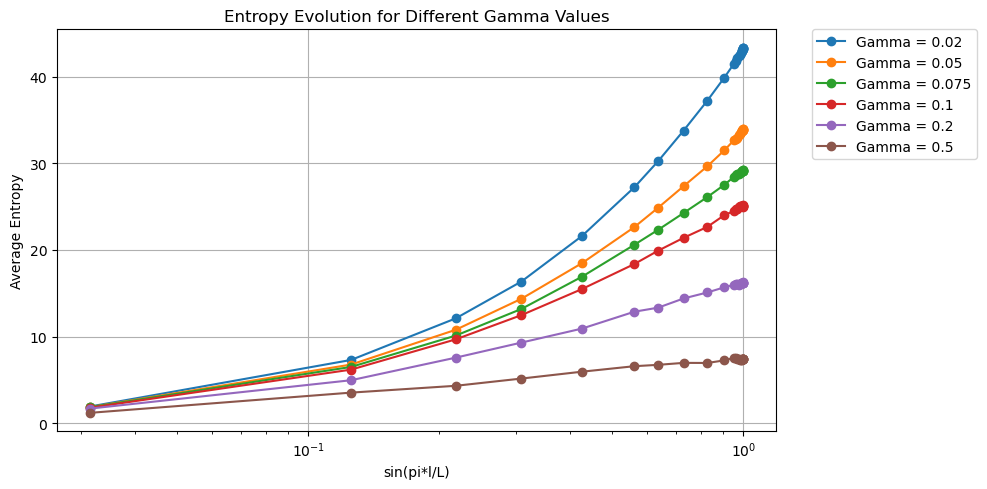

In [499]:
plt.figure(figsize=(10, 5))
for gamma, avg_entropy in gamma_entropies.items():
    plt.plot([ sin(i,200) for i in l][:], avg_entropy[:], '-o',label=f"Gamma = {gamma}")

plt.xscale('log')
plt.xlabel("sin(pi*l/L)")
plt.ylabel("Average Entropy")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0)  # Move the legend outside
plt.title("Entropy Evolution for Different Gamma Values")
plt.grid()
plt.tight_layout()  # Adjust the layout to avoid clipping
plt.show()

In [500]:
N=150
dt = 0.05
time = np.arange(0,N+dt,dt)
traj = 10

gamma_values = [ 0.05, 0.15, 0.1, 0.25, 0.2,0.35,0.3,0.4,0.5,0.6,0.8,1.0,1.5,2.0,4.0,6.0]
gamma_entropiesz = {}

for gamma in tqdm(gamma_values):
    traj_entropies = []
    
    for t in range(traj):
        
        Dm = []

        Ham =H(300)
        U_init, _ = initial(300)
        for t in range(len(time)):    
            Dm.append(U_init)    
            U_initx,U_init,_,_ = evolutionx(U_init,Ham,gamma,dt)


        Matrix = [(x@x.conj().T).T for x in Dm]
        Mat2 = [Matrix[i][:150,:150] for i in range(len(Matrix))]
        alleigval = [np.linalg.eig(Mat2[i])[0] for i in range(len(Mat2))]
        S = []
        for i in range(len(alleigval)):
            S.append(np.sum([entropy(x) for x in alleigval[i]]))        
        traj_entropies.append(S)


    average_entropy = np.mean(traj_entropies, axis=0)


    gamma_entropiesz[gamma] = average_entropy


  0%|          | 0/16 [00:00<?, ?it/s]

 56%|█████▋    | 9/16 [11:24:44<8:52:34, 4564.96s/it]


KeyboardInterrupt: 

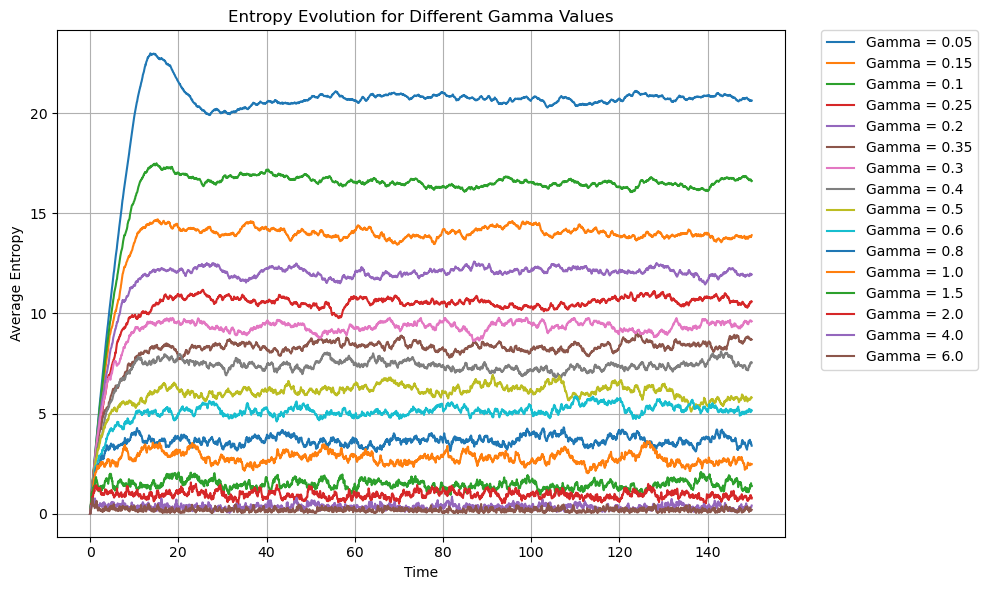

In [266]:
plt.figure(figsize=(10, 6))
for gamma, avg_entropy in gamma_entropiesz.items():
    plt.plot(time, avg_entropy, label=f"Gamma = {gamma}")

plt.xlabel("Time")
plt.ylabel("Average Entropy")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0)  # Move the legend outside
plt.title("Entropy Evolution for Different Gamma Values")
plt.grid()
plt.tight_layout()  # Adjust the layout to avoid clipping
plt.show()

In [8]:
gamma_values = [0.25, 2.0, 6.0]
data_qsd = [np.random.normal(15, 1, 5000), np.random.normal(1, 0.5, 5000), np.random.normal(0.5, 0.2, 5000)]
data_qsdc = [np.random.normal(18.5, 1, 5000), np.random.normal(6, 1, 5000), np.random.normal(3.5, 0.8, 5000)]


In [15]:
len(data_qsd[0])

5000

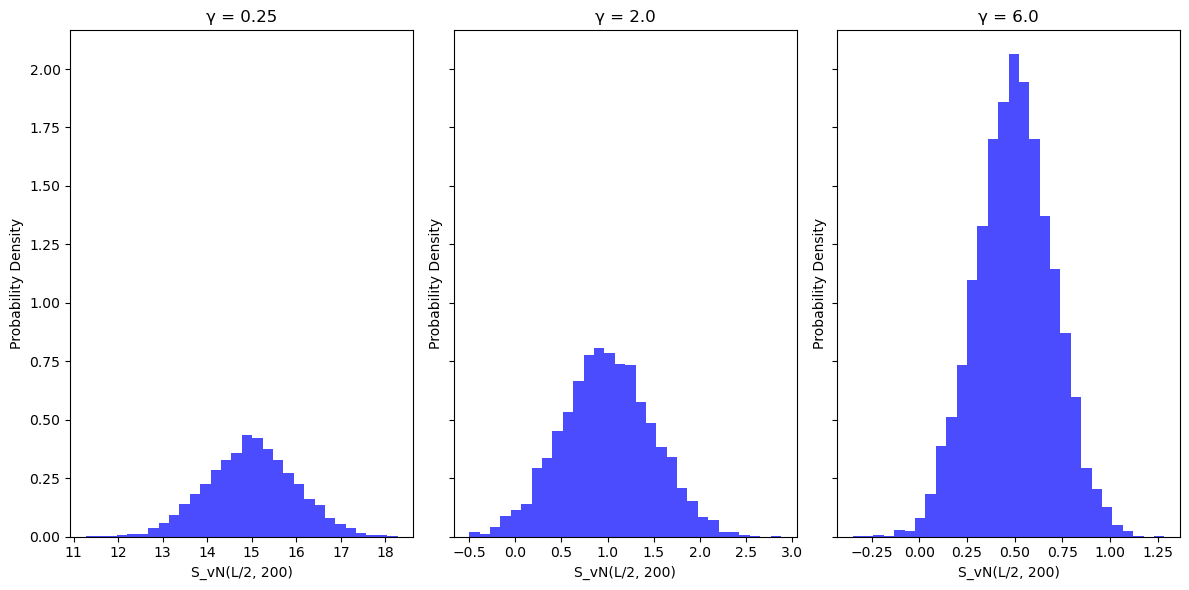

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
for i, gamma in enumerate(gamma_values):
    axes[ i].hist(data_qsd[i], bins=30, density=True, color='blue', alpha=0.7)
    axes[i].set_title(f"γ = {gamma}")
    axes[i].set_xlabel("S_vN(L/2, 200)")
    axes[i].set_ylabel("Probability Density")
    


plt.tight_layout()
plt.show()